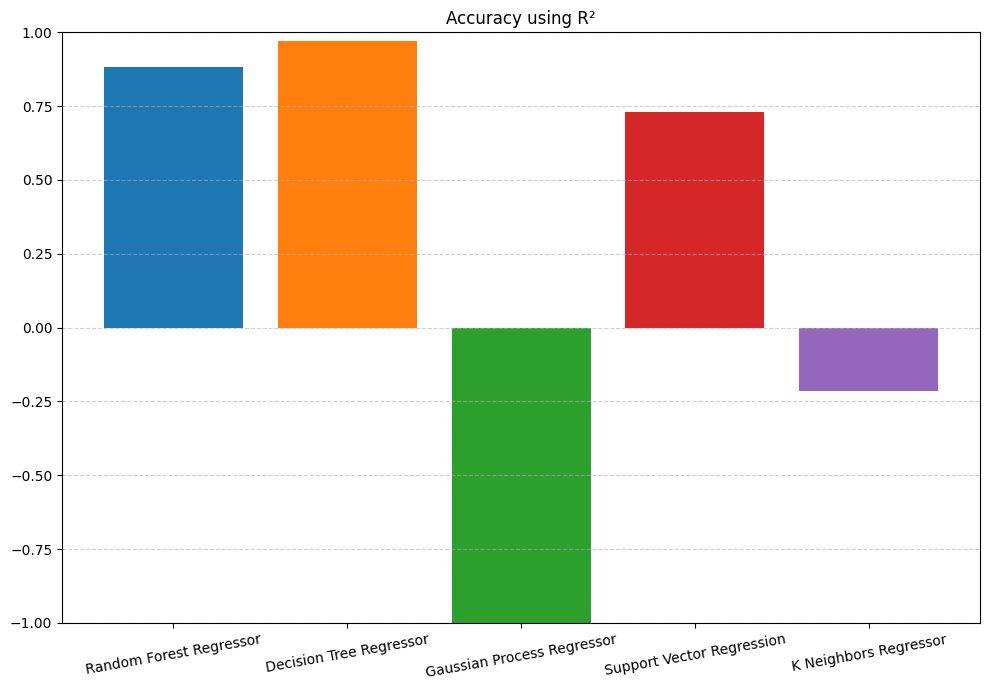

In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------
df = pd.read_csv("Efficiency.csv")

# CHANGE THIS to your actual target column name
X = df[['Frequency_in_GHz']].values
y = df['Rad_effi_in_mag'].values

# --------------------------------------------------
# 2. Train-test split
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------------------------------------------------
# 3. Define ML models
# --------------------------------------------------
models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=120, random_state=42),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Gaussian Process Regressor": GaussianProcessRegressor(random_state=42),
    "Support Vector Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf"))
    ]),
    "K Neighbors Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor())
    ])
}

# --------------------------------------------------
# 4. Train models and compute R²
# --------------------------------------------------
r2_scores = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2_scores[name] = r2_score(y_test, y_pred)


# --------------------------------------------------
# 5. Plot R² bar chart (like your figure)
# --------------------------------------------------
plt.figure(figsize=(10,7))


colors = ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd"]

bars = plt.bar(
    list(r2_scores.keys()),
    list(r2_scores.values()),
    color=colors
)
plt.xticks(rotation=10)

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.ylim(-1,1)

plt.title("Accuracy using R²")

plt.tight_layout()

plt.savefig("yaxisefficiency_prediction.png", dpi=600)

plt.show()


In [ ]:
#plt.figure(figsize=(10,7))

colors = ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd"]

bars = plt.bar(
    list(r2_scores.keys()),
    list(r2_scores.values()),
    color=colors
)

for bar in bars:
    
    height = bar.get_height()
    
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.03,
        f"{height*100:.1f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )